# 04 — Du score à la probabilité : le softmax et le *forward pass*

**Chapitre 1** · durée conseillée : 20 min · CPU uniquement · [![Ouvrir dans Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/zenocode-org/ai-masterclass/blob/main/fr/chapitre_1/04_softmax_forward_pass.ipynb)

![Parcours du chapitre](https://raw.githubusercontent.com/zenocode-org/ai-masterclass/main/fr/chapitre_1/figures/00_parcours.png)

**Où en sommes-nous ?**
- **Notebook 02 :** une **loss** note un modèle à partir de la probabilité qu'il donne à la bonne réponse : $-\log(p)$.
- **Notebook 03 :** `one_hot(x) @ W` donne **27 scores** pour chaque caractère courant.
- **Ce qui manque :** ces scores ne sont pas des probabilités, on ne peut donc pas leur appliquer la loss.

Il nous faut une transformation qui garantisse deux propriétés : chaque valeur **entre 0 et 1**, et les 27 valeurs d'une ligne **de somme 1**.

**Pourquoi ne pas stocker directement des probabilités dans `W` ?** Parce qu'en modifiant librement un poids pendant l'entraînement, on pourrait créer un nombre négatif ou casser la somme à 1. On laisse donc `W` contenir des **scores sans contrainte**, appelés **logits**, et on les transforme ensuite. L'entraînement pourra modifier `W` comme il veut.

In [ ]:
# Sur Google Colab : récupérer le dépôt du cours (corpus + modules partagés comme bigramme.py).
# En local, cette cellule ne fait rien.
import os, sys
if "google.colab" in sys.modules and not os.path.exists("bigramme.py"):
    if not os.path.exists("ai-masterclass"):
        !git clone -q --depth 1 https://github.com/zenocode-org/ai-masterclass
    %cd ai-masterclass/fr/chapitre_1

In [1]:
# Préparation : imports et petit module partagé du chapitre
import math
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

import bigramme  # fichier bigramme.py, à côté de ce notebook
from bigramme import SEED, plot_matrice_caracteres

words = bigramme.charger_prenoms()
chars, stoi, itos = bigramme.construire_vocabulaire(words)
print(f"{len(words):,} prénoms · vocabulaire de {len(stoi)} symboles · PyTorch {torch.__version__}")

N = bigramme.compter_bigrammes(words, stoi)
P = N.float() / N.sum(dim=1, keepdim=True)

32,033 prénoms · vocabulaire de 27 symboles · PyTorch 2.14.1+cu130


## 1. Première difficulté : des scores négatifs

Trois caractères fictifs `a`, `b`, `c`, avec ces logits :

| caractère suivant | `a` | `b` | `c` |
|---|---:|---:|---:|
| logit | −1 | 0 | 1 |

Le score 1 exprime une **préférence** plus forte pour `c`. Mais 1 n'est pas « 100 % », et −1 ne peut pas être une probabilité.

Il nous faut une fonction qui :
- rend **tout nombre réel strictement positif** ;
- **conserve l'ordre** : un score plus haut garde un poids plus grand ;
- est **dérivable**, pour pouvoir entraîner `W` par gradient.

L'**exponentielle** coche les trois cases : $e^{-1}\approx 0{,}368$, $e^0=1$, $e^1\approx 2{,}718$.

> Dans le code, ces valeurs s'appellent souvent `counts`, par analogie avec des comptages. **Ce ne sont pas** les comptes de `N`. La section 4 montre pourquoi l'analogie est pourtant très juste.

a : logit = -1.0  →  exp(logit) = 0.368
b : logit = +0.0  →  exp(logit) = 1.000
c : logit = +1.0  →  exp(logit) = 2.718
Somme des poids : 4.086 → pas encore 1


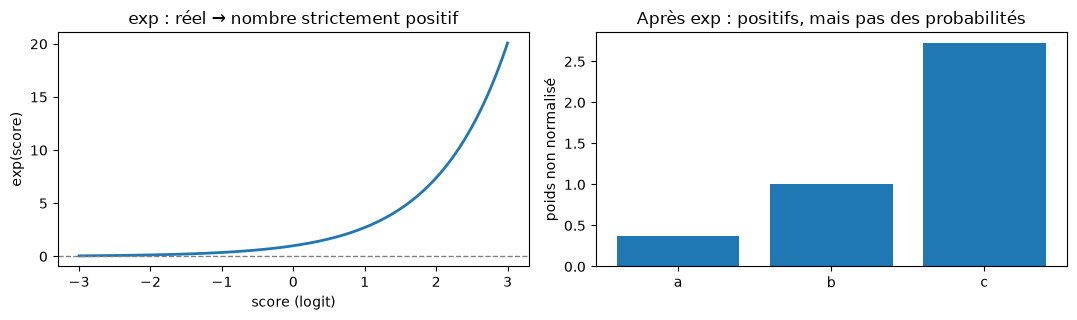

In [2]:
logits_jouet = torch.tensor([-1.0, 0.0, 1.0])
poids_jouet = logits_jouet.exp()

for c, s, w in zip("abc", logits_jouet, poids_jouet):
    print(f"{c} : logit = {s.item():+.1f}  →  exp(logit) = {w.item():.3f}")
print("Somme des poids :", round(poids_jouet.sum().item(), 3), "→ pas encore 1")

z = torch.linspace(-3, 3, 250)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.3))
axes[0].plot(z.numpy(), z.exp().numpy(), linewidth=2)
axes[0].axhline(0, color="gray", linestyle="--", linewidth=1)
axes[0].set(title="exp : réel → nombre strictement positif", xlabel="score (logit)", ylabel="exp(score)")
axes[1].bar(list("abc"), poids_jouet.numpy())
axes[1].set(title="Après exp : positifs, mais pas des probabilités", ylabel="poids non normalisé")
plt.tight_layout(); plt.show()

## 2. Deuxième difficulté : la somme ne vaut pas 1

Les poids valent environ $[0{,}368;\ 1;\ 2{,}718]$, de somme $\approx 4{,}086$. Comme au notebook 01, pour transformer des poids positifs en proportions, **on divise chacun par la somme** :

$$
p_j = \frac{e^{s_j}}{\sum_k e^{s_k}}.
$$

Ici, on obtient $[0{,}090;\ 0{,}245;\ 0{,}665]$. Chaque valeur est entre 0 et 1 et leur somme vaut 1.

La combinaison **exponentielle puis division par la somme** s'appelle le **softmax**. Le nom vient de ce qu'il se comporte comme un `max` « adouci » : le plus grand score reçoit la plus grande part, sans que les autres tombent à zéro.

> **Ne pas confondre :** le softmax calcule une **distribution**. Il ne choisit pas de caractère. C'est `torch.multinomial` (notebook 01) qui tire un caractère dans cette distribution.

a : logit = -1.0 | exp = 0.368 | p = 0.090
b : logit = +0.0 | exp = 1.000 | p = 0.245
c : logit = +1.0 | exp = 2.718 | p = 0.665
Identique à torch.softmax : oui


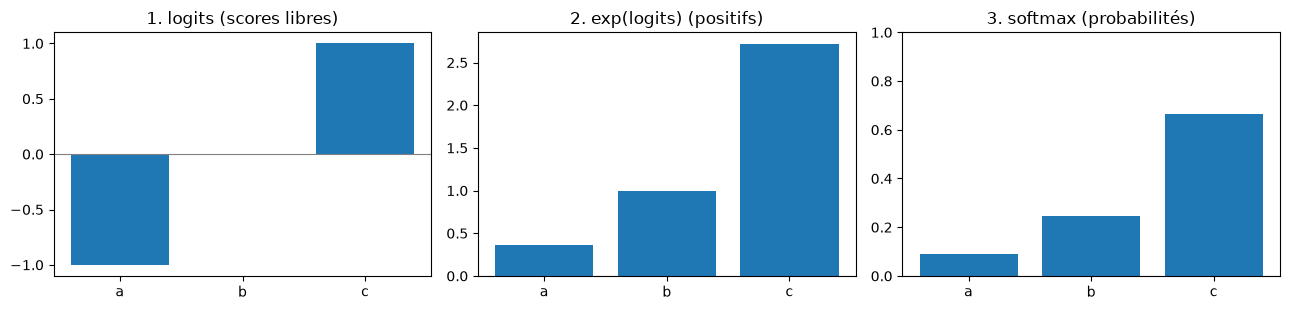

In [3]:
probs_jouet = poids_jouet / poids_jouet.sum()
for c, s, w, p in zip("abc", logits_jouet, poids_jouet, probs_jouet):
    print(f"{c} : logit = {s.item():+.1f} | exp = {w.item():.3f} | p = {p.item():.3f}")
assert torch.allclose(probs_jouet, torch.softmax(logits_jouet, dim=0))
print("Identique à torch.softmax : oui")

fig, axes = plt.subplots(1, 3, figsize=(13, 3.2))
for ax, val, titre in zip(axes, [logits_jouet, poids_jouet, probs_jouet],
                          ["1. logits (scores libres)", "2. exp(logits) (positifs)", "3. softmax (probabilités)"]):
    ax.bar(list("abc"), val.numpy()); ax.set_title(titre); ax.axhline(0, color="gray", linewidth=0.8)
axes[2].set_ylim(0, 1)
plt.tight_layout(); plt.show()

## 3. Trois propriétés du softmax à connaître

1. **Ajouter la même constante à tous les logits ne change rien.** $e^{s_j + c} / \sum_k e^{s_k + c}$ : le facteur $e^c$ se simplifie. Seules les **différences** entre scores comptent.
2. **Multiplier les logits par un nombre** rend la distribution plus pointue (facteur > 1) ou plus plate (facteur < 1). C'est le principe de la **température**, utilisée au chapitre 2 pour la génération.
3. **Des logits très grands font déborder `exp`** (`exp(1000) = inf`). `torch.softmax` utilise la propriété 1 : il soustrait le maximum avant d'appliquer `exp`, et le calcul reste exact.

In [4]:
s = torch.tensor([-1.0, 0.0, 1.0])
print("softmax(s)       :", torch.softmax(s, 0).round(decimals=3).tolist())
print("softmax(s + 100) :", torch.softmax(s + 100, 0).round(decimals=3).tolist(), " ← identique")
print("softmax(3 * s)   :", torch.softmax(3 * s, 0).round(decimals=3).tolist(), " ← plus pointu")
print("softmax(s / 3)   :", torch.softmax(s / 3, 0).round(decimals=3).tolist(), " ← plus plat")

grand = torch.tensor([1000.0, 1001.0, 1002.0])
naif = grand.exp() / grand.exp().sum()
print("\nVersion naïve sur [1000, 1001, 1002] :", naif.tolist())
print("torch.softmax                        :", torch.softmax(grand, 0).round(decimals=3).tolist())

softmax(s)       : [0.09000000357627869, 0.24500000476837158, 0.6650000214576721]
softmax(s + 100) : [0.09000000357627869, 0.24500000476837158, 0.6650000214576721]  ← identique
softmax(3 * s)   : [0.0020000000949949026, 0.04699999839067459, 0.949999988079071]  ← plus pointu
softmax(s / 3)   : [0.23000000417232513, 0.32100000977516174, 0.4480000138282776]  ← plus plat

Version naïve sur [1000, 1001, 1002] : [nan, nan, nan]
torch.softmax                        : [0.09000000357627869, 0.24500000476837158, 0.6650000214576721]


## 4. La remarque qui relie tout : les logits sont des « log-comptes »

Pourquoi appeler `counts` les valeurs `exp(logits)` ? Supposons qu'on choisisse $W_{ij} = \log N_{ij}$. Alors

$$
\mathrm{softmax}(W_i)_j = \frac{e^{\log N_{ij}}}{\sum_k e^{\log N_{ik}}} = \frac{N_{ij}}{\sum_k N_{ik}} = P_{ij}.
$$

Le softmax de cette matrice redonne **exactement la table de comptage**. Autrement dit, la bonne réponse **existe** parmi toutes les valeurs possibles de `W`. L'entraînement devra la retrouver tout seul, sans jamais voir `N`. Les comptes nuls posent problème (`log 0 = −∞`), donc on utilise la version lissée `N + 1` du notebook 02.

In [5]:
W_log = (N + 1).float().log()              # logits = log des comptes (lissés)
P_lisse = (N + 1).float() / (N + 1).sum(dim=1, keepdim=True)
print("softmax(log(N+1)) == P lissée ?", torch.allclose(torch.softmax(W_log, dim=1), P_lisse, atol=1e-6))

softmax(log(N+1)) == P lissée ? True


## 5. Le *forward pass* complet sur `emma`

![Forward pass](https://raw.githubusercontent.com/zenocode-org/ai-masterclass/main/fr/chapitre_1/figures/04_forward_pass.png)

On applique maintenant la recette avec **27 caractères** et les **5 transitions d'`emma`**. `W` est tirée au hasard (`torch.randn`), sans utiliser `N` ni `P` : ses prédictions sont donc **non entraînées**.

1. `xenc = F.one_hot(xs_small)` : 5 entrées de 27 cases → `(5, 27)` ;
2. `logits = xenc @ W` : les 5 lignes de scores sélectionnées dans `W` → `(5, 27)` ;
3. `counts = logits.exp()` : des poids strictement positifs → `(5, 27)` ;
4. `probs = counts / counts.sum(dim=1, keepdim=True)` : **chaque ligne** divisée par **sa** somme → `(5, 27)`.

`dim=1` correspond aux 27 caractères de sortie : on normalise **chaque exemple séparément**, sans mélanger les 5 exemples. `keepdim=True` donne des sommes de forme `(5, 1)`, comme au notebook 01.

In [6]:
sequence = ["."] + list("emma") + ["."]
transitions = list(zip(sequence, sequence[1:]))
xs_small = torch.tensor([stoi[a] for a, b in transitions])
ys_small = torch.tensor([stoi[b] for a, b in transitions])

g = torch.Generator().manual_seed(SEED)
W = torch.randn((27, 27), generator=g)

# LES QUATRE LIGNES À RETENIR : le forward pass du bigramme neuronal
xenc = F.one_hot(xs_small, num_classes=27).float()             # (5, 27) entrées
logits = xenc @ W                                              # (5, 27) scores libres
counts = logits.exp()                                          # (5, 27) positifs (ce n'est PAS N)
probs = counts / counts.sum(dim=1, keepdim=True)               # (5, 27) probabilités

print("Sommes des lignes avant division :", counts.sum(dim=1).round(decimals=2).tolist())
print("Sommes des lignes après division :", probs.sum(dim=1).round(decimals=4).tolist())
print("Identique à F.softmax(logits, dim=1) ?", torch.allclose(probs, F.softmax(logits, dim=1)))

Sommes des lignes avant division : [79.01000213623047, 55.33000183105469, 38.90999984741211, 38.90999984741211, 34.15999984741211]
Sommes des lignes après division : [1.0, 1.0, 1.0, 1.0, 1.0]
Identique à F.softmax(logits, dim=1) ? True


## 6. Lire une probabilité *produite par le réseau*

Nous avons maintenant deux réponses à la même question : « après `m`, quelle est la probabilité de `a` ? »
- **Table `P` (notebook 01) :** `P[stoi['m'], stoi['a']]`, une **fréquence observée** ;
- **Réseau non entraîné :** `probs[3, stoi['a']]`, le softmax de la ligne `W['m']`. L'exemple n° 4 d'`emma` est justement `m → a` (indice 3 en Python).

Ces deux nombres n'ont **aucune raison d'être proches** pour l'instant : `W` est aléatoire.

m → a selon le comptage P : 0.3899
m → a selon W aléatoire   : 0.0737


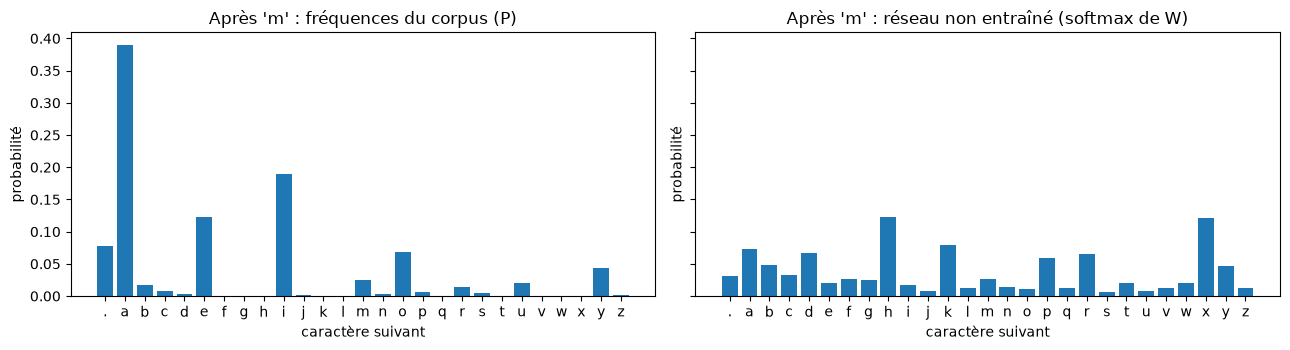

In [7]:
i_m, i_a = stoi["m"], stoi["a"]
print(f"m → a selon le comptage P : {P[i_m, i_a].item():.4f}")
print(f"m → a selon W aléatoire   : {probs[3, i_a].item():.4f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 3.6), sharey=True)
for ax, dist, titre in zip(axes, [P[i_m], probs[3]],
                           ["Après 'm' : fréquences du corpus (P)", "Après 'm' : réseau non entraîné (softmax de W)"]):
    ax.bar(range(27), dist.numpy())
    ax.set_xticks(range(27), [itos[i] for i in range(27)])
    ax.set(title=titre, xlabel="caractère suivant", ylabel="probabilité")
plt.tight_layout(); plt.show()

## 7. La loss devient calculable

La boucle commencée au notebook 02 se referme :
- les **bonnes réponses** `ys_small` sont connues ;
- `probs` contient 5 lignes de **probabilités prédites** ;
- dans chaque ligne, on lit **la probabilité de la bonne réponse** et on calcule la **même NLL moyenne** qu'avant.

Pour l'exemple $t$, la probabilité utile est `probs[t, ys_small[t]]`, et sa pénalité vaut $-\log$ de cette probabilité.

In [8]:
p_vraies = probs[torch.arange(5), ys_small]      # une probabilité par exemple (détaillé au notebook 05)
couts = -p_vraies.log()
for (a, b), p, c in zip(transitions, p_vraies, couts):
    print(f"  {a} → {b} : p = {p.item():.4f}   −log p = {c.item():.3f}")
print(f"NLL moyenne du réseau aléatoire sur emma : {couts.mean().item():.3f}")

P_lisse = (N + 1).float() / (N + 1).sum(dim=1, keepdim=True)
print(f"NLL de la table P sur emma               : {-P_lisse[xs_small, ys_small].log().mean().item():.3f}")

  . → e : p = 0.0123   −log p = 4.399
  e → m : p = 0.0181   −log p = 4.015
  m → m : p = 0.0267   −log p = 3.623
  m → a : p = 0.0737   −log p = 2.608
  a → . : p = 0.0150   −log p = 4.201
NLL moyenne du réseau aléatoire sur emma : 3.769
NLL de la table P sur emma               : 2.514


Le réseau aléatoire fait **bien pire** que le comptage, et même que l'uniforme (3,30). C'est normal : il n'a rien appris.

**Attention :** calculer la loss **ne modifie pas `W`**. Pour améliorer les prédictions, il faut savoir **dans quel sens bouger chaque poids** pour faire baisser la loss. C'est le rôle des **gradients**, au notebook 05.

## Bilan

$$
\boxed{\text{indices}\xrightarrow{\text{one-hot}}(n,27)\xrightarrow{@W}\text{logits}\xrightarrow{\exp}\text{counts}\xrightarrow{/\text{somme}}\text{probs}\xrightarrow{[\,\cdot\,,\,y]}p_\text{vraie}\xrightarrow{-\log,\ \text{moyenne}}\text{loss}}
$$

- **logits** = scores libres, n'importe quel réel ;
- **softmax** = `exp` puis normalisation, qui donne une distribution ;
- `softmax(log N) = P` : le comptage est **une valeur particulière** de `W`.

Le *forward pass* est terminé, l'apprentissage peut commencer.

## Références
- J. S. Bridle, *Probabilistic Interpretation of Feedforward Classification Network Outputs, with Relationships to Statistical Pattern Recognition*, 1990 : l'article qui popularise le nom « softmax ».
- I. Goodfellow, Y. Bengio et A. Courville, [*Deep Learning*](https://www.deeplearningbook.org/), 2016, section 6.2.2.3 « Softmax Units » et section 4.1 (débordements numériques et softmax stable).
- Andrej Karpathy, [*The spelled-out intro to language modeling: building makemore*](https://www.youtube.com/watch?v=PaCmpygFfXo) (2022) et le dépôt [makemore](https://github.com/karpathy/makemore), dont viennent `names.txt` et l'esprit de ce chapitre.